# Báo cáo thực nghiệm MAG-BERT từ CSV đã lưu
Chạy riêng trên CPU sau khi mount Drive. Không cần notebook 03, PyTorch, BERT,
checkpoint, dữ liệu pkl hay chạy suy luận. Nguồn: 6 training_history.csv và
6 test_predictions.csv; seed_runs.csv quyết định trial_dir kể cả seed 42.
Cell 1: đường dẫn; 2: hàm đọc; 3: đọc/đối chiếu; 4–5: hai hình;
6: CSV; 7: nhận xét từ dự đoán và danh sách đầu ra.
Biểu đồ: Frozen BERT xanh #1f77b4, Fine-tune BERT cam #ff7f0e.
Notebook Self-MM trên main chưa có mã vẽ; đây là quy ước chung có thể tái dùng,
không khẳng định là màu của một hình Self-MM đã được xác minh.


In [1]:
# Cell 1 — Mount Drive và khai báo đường dẫn
import os
import sys
import json
from pathlib import Path, PurePosixPath
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display

if os.environ.get("MAGBERT_LOCAL_REPORT") != "1":
    from google.colab import drive
    drive.mount("/content/drive")

RESULT_ROOT = Path(os.environ.get(
    "MAGBERT_RESULT_ROOT",
    "/content/drive/MyDrive/CMU-MOSI/training/MAG_BERT_BaoHoang_search",
))
OUTPUT_DIR = Path(os.environ.get(
    "MAGBERT_REPORT_OUTPUT", str(RESULT_ROOT / "final_report/paper_figures"),
))
COMPARISON_DIR = Path(os.environ.get(
    "MAGBERT_COMPARISON_DIR", str(RESULT_ROOT.parent / "model_comparison"),
))
SEEDS = (21, 42, 123)
STRATEGIES = ("frozen", "finetune")
LABELS = {"frozen": "Frozen BERT", "finetune": "Fine-tune BERT"}
COLORS = {"frozen": "#1f77b4", "finetune": "#ff7f0e"}
MARKERS = {"frozen": "s", "finetune": "o"}
VARIANT = "aligned_p99"
METRICS = ["MAE", "Corr", "Acc-2", "Macro-F1"]
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "pdf.fonttype": 42, "ps.fonttype": 42,
    "axes.axisbelow": True,
})
print("Read saved results:", RESULT_ROOT)
print("Paper outputs:", OUTPUT_DIR)
print("Comparison CSV:", COMPARISON_DIR / "magbert_aligned_test.csv")



Read saved results: H:\AI\Data Mining\magbert_paper_report\inputs\MAG_BERT_BaoHoang_search
Paper outputs: H:\AI\Data Mining\magbert_paper_report\outputs
Comparison CSV: H:\AI\Data Mining\magbert_paper_report\inputs\model_comparison\magbert_aligned_test.csv


In [2]:
# Cell 2 — Các hàm đọc CSV và tìm trial theo seed_runs.csv
def read_saved_csv(path, **kwargs):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f"Thiếu CSV đã lưu: {path}. Kiểm tra RESULT_ROOT ở Cell 1.")
    return pd.read_csv(path, float_precision="round_trip", **kwargs)


def resolve_saved_trial_dir(saved_trial_dir, result_root):
    # Rebase đường dẫn /content/drive cũ sang bản copy hiện tại.
    # Không suy đoán trial_dir từ seed; seed 42 nằm ngoài multiple_seeds.
    parts = PurePosixPath(str(saved_trial_dir).replace("\\", "/")).parts
    anchor = "MAG_BERT_BaoHoang_search"
    if anchor not in parts:
        raise ValueError(f"trial_dir không có thư mục gốc đã xác minh: {saved_trial_dir}")
    relative = Path(*parts[parts.index(anchor) + 1:])
    target = (Path(result_root) / relative).resolve()
    if not target.is_relative_to(Path(result_root).resolve()):
        raise ValueError("trial_dir vượt ngoài RESULT_ROOT")
    return target


def load_saved_experiment_tables(result_root):
    multi = Path(result_root) / "multiple_seeds"
    runs = read_saved_csv(multi / "seed_runs.csv")
    tests = read_saved_csv(multi / "test_results_each_seed.csv")
    expected_keys = {(s, seed) for s in STRATEGIES for seed in SEEDS}
    for name, table in [("seed_runs", runs), ("test_results", tests)]:
        keys = list(zip(table["strategy"], table["seed"]))
        if len(keys) != 6 or set(keys) != expected_keys:
            raise ValueError(f"{name} phải có đúng 6 lượt Frozen/Fine-tune × 3 seed.")
    if not (tests["samples"].eq(686) & tests["acc2_samples"].eq(656)).all():
        raise ValueError("Số mẫu test không khớp 686/656.")
    histories, prediction_paths, records = {}, {}, []
    test_index = tests.set_index(["strategy", "seed"])
    for row in runs.itertuples(index=False):
        key = (row.strategy, int(row.seed))
        trial = resolve_saved_trial_dir(row.trial_dir, result_root)
        history_path = trial / "training_history.csv"
        history = read_saved_csv(history_path).sort_values("epoch")
        if history["epoch"].duplicated().any() or not np.isfinite(history["valid_MAE"]).all():
            raise ValueError(f"Log không hợp lệ: {history_path}")
        if not np.array_equal(history["epoch"], np.arange(1, len(history) + 1)):
            raise ValueError(f"Log thiếu epoch: {history_path}")
        best = history.loc[history["valid_MAE"].idxmin()]
        if int(best["epoch"]) != int(row.best_epoch):
            raise ValueError(f"best_epoch không phải epoch MAE nhỏ nhất: {key}")
        if not np.isclose(best["valid_MAE"], row.best_valid_MAE, rtol=0, atol=1e-12):
            raise ValueError(f"MAE của checkpoint không khớp log: {key}")
        saved_test = test_index.loc[key]
        if int(saved_test["checkpoint_epoch"]) != int(row.best_epoch):
            raise ValueError(f"Checkpoint test khác checkpoint đã chọn: {key}")
        if not np.isclose(saved_test["valid_MAE"], row.best_valid_MAE, rtol=0, atol=1e-12):
            raise ValueError(f"Validation MAE trong bảng test không khớp: {key}")
        histories[key] = history
        prediction_paths[key] = trial / "test_predictions.csv"
        records.append({
            "strategy": row.strategy, "seed": int(row.seed),
            "logged_epochs": len(history), "best_epoch": int(row.best_epoch),
            "best_valid_MAE": float(best["valid_MAE"]),
            "trial_dir_from_csv": row.trial_dir,
            "resolved_trial_dir": str(trial),
            "training_history_csv": str(history_path),
            "test_predictions_csv": str(prediction_paths[key]),
        })
    frozen42 = histories[("frozen", 42)]
    assert len(frozen42) == 7 and int(frozen42["epoch"].max()) == 7
    assert int(runs.set_index(["strategy", "seed"]).loc[("frozen", 42), "best_epoch"]) == 2
    return runs, tests, histories, prediction_paths, pd.DataFrame(records)


def summarize_saved_test_results(tests, result_root):
    summary = tests.groupby("strategy")[METRICS].agg(["mean", "std"])
    saved = read_saved_csv(
        Path(result_root) / "multiple_seeds/test_mean_std_numeric.csv",
        header=[0, 1], index_col=0,
    )
    for strategy in STRATEGIES:
        for metric in METRICS:
            for stat in ("mean", "std"):
                if not np.isclose(summary.loc[strategy, (metric, stat)],
                                  saved.loc[strategy, (metric, stat)], rtol=0, atol=1e-12):
                    raise ValueError(f"Thống kê đã lưu không khớp: {strategy}/{metric}/{stat}")
    # Đối chiếu các giá trị hiển thị đã thống nhất; nguồn số vẫn là CSV.
    assert f"{summary.loc['finetune', ('MAE', 'mean')]:.4f}" == "0.7988"
    assert f"{summary.loc['finetune', ('MAE', 'std')]:.4f}" == "0.0285"
    assert f"{summary.loc['frozen', ('MAE', 'mean')]:.4f}" == "1.4664"
    assert f"{summary.loc['frozen', ('MAE', 'std')]:.4f}" == "0.0528"
    return summary


def save_paper_figure(fig, stem, output_dir):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    fig.savefig(output_dir / f"{stem}.pdf", bbox_inches="tight")
    fig.savefig(output_dir / f"{stem}.png", dpi=300, bbox_inches="tight")



In [3]:
# Cell 3 — Đọc log và bảng test đã có; kiểm tra mean/std, không đánh giá mô hình
runs, tests, histories, prediction_paths, source_table = load_saved_experiment_tables(RESULT_ROOT)
summary = summarize_saved_test_results(tests, RESULT_ROOT)
display(source_table[["strategy", "seed", "logged_epochs", "best_epoch", "best_valid_MAE"]]
        .style.format({"best_valid_MAE": "{:.4f}"}))
display(summary.style.format("{:.4f}"))
print("Thống kê dùng sample standard deviation, ddof=1.")



   strategy  seed  logged_epochs  best_epoch  best_valid_MAE
0  finetune    21             10           9        0.753922
1  finetune    42             10           8        0.802383
2  finetune   123             10           9        0.849687
3    frozen    21             10          10        1.430505
4    frozen    42              7           2        1.418518
5    frozen   123             10          10        1.436732

               MAE                Corr                Acc-2            Macro-F1          
              mean       std      mean       std       mean       std      mean       std
strategy                                                                                 
finetune  0.798825  0.028530  0.767032  0.014212  83.434959  1.383197  0.830630  0.013343
frozen    1.466388  0.052791  0.048479  0.113515  47.052846  8.361018  0.385092  0.152768

Thống kê dùng sample standard deviation, ddof=1.


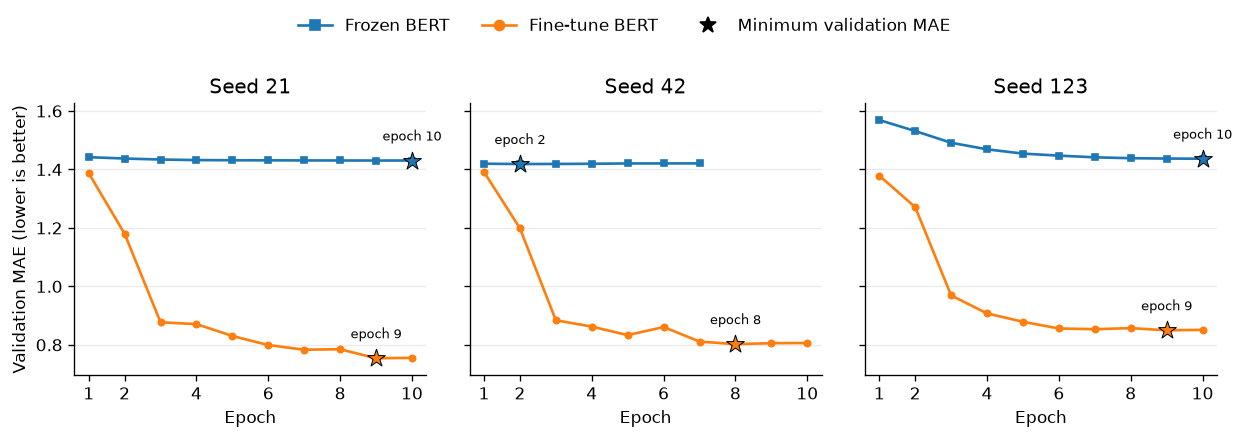

Frozen seed 42 kết thúc ở epoch 7, dấu sao ở epoch 2; không kéo dài/điền log.


In [4]:
# Cell 4 — Validation MAE theo epoch, ba ô chung thang trục y
def plot_validation_mae_by_seed(histories, runs, output_dir):
    fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.65), sharex=True, sharey=True)
    lookup = runs.set_index(["strategy", "seed"])
    all_mae = np.concatenate([h["valid_MAE"].to_numpy() for h in histories.values()])
    pad = (all_mae.max() - all_mae.min()) * 0.07
    for ax, seed in zip(axes, SEEDS):
        for strategy in STRATEGIES:
            history = histories[(strategy, seed)]
            ax.plot(history["epoch"], history["valid_MAE"],
                    color=COLORS[strategy], marker=MARKERS[strategy],
                    markersize=3.8, linewidth=1.6, label=LABELS[strategy])
            epoch = int(lookup.loc[(strategy, seed), "best_epoch"])
            value = float(history.set_index("epoch").loc[epoch, "valid_MAE"])
            ax.scatter(epoch, value, s=125, marker="*", color=COLORS[strategy],
                       edgecolors="black", linewidths=0.6, zorder=5)
            offset = (0, 12)
            ax.annotate(f"epoch {epoch}", (epoch, value), xytext=offset,
                        textcoords="offset points", ha="center", fontsize=8)
        ax.set(title=f"Seed {seed}", xlabel="Epoch", xlim=(0.6, 10.4),
               ylim=(all_mae.min() - pad, all_mae.max() + pad))
        ax.set_xticks([1, 2, 4, 6, 8, 10])
        ax.grid(axis="y", alpha=0.25)
    axes[0].set_ylabel("Validation MAE (lower is better)")
    handles = [Line2D([0], [0], color=COLORS[s], marker=MARKERS[s],
                      label=LABELS[s], linewidth=1.6) for s in STRATEGIES]
    handles.append(Line2D([0], [0], color="black", marker="*", linestyle="None",
                          markersize=10, label="Minimum validation MAE"))
    fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 1.01),
               ncol=3, frameon=False)
    fig.tight_layout(rect=(0, 0, 1, 0.88))
    save_paper_figure(fig, "magbert_validation_mae_by_seed", output_dir)
    return fig


validation_figure = plot_validation_mae_by_seed(histories, runs, OUTPUT_DIR)
plt.show()
print("Frozen seed 42 kết thúc ở epoch 7, dấu sao ở epoch 2; không kéo dài/điền log.")



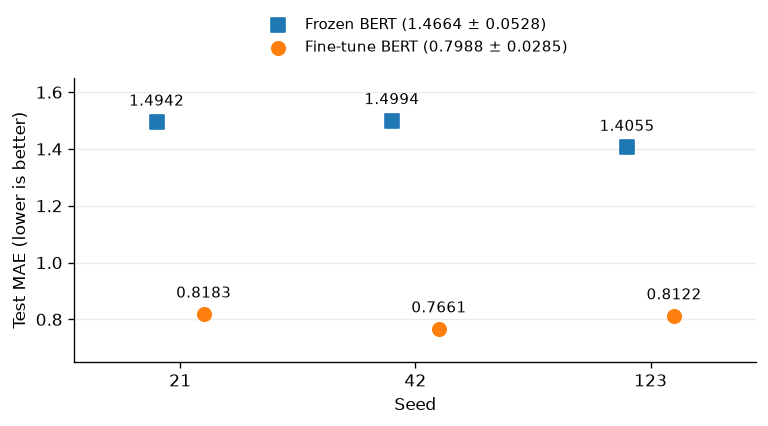

Mỗi điểm dùng checkpoint đã chọn bằng validation MAE; không chọn lại bằng test.


In [5]:
# Cell 5 — Test MAE lấy trực tiếp từ bảng CSV, hai điểm cạnh nhau theo seed
def plot_test_mae_by_seed(tests, summary, output_dir):
    fig, ax = plt.subplots(figsize=(6.5, 3.8))
    centers = np.arange(len(SEEDS))
    for strategy, offset in zip(STRATEGIES, (-0.1, 0.1)):
        values = tests.loc[tests["strategy"].eq(strategy)].set_index("seed").loc[list(SEEDS), "MAE"]
        mean = summary.loc[strategy, ("MAE", "mean")]
        std = summary.loc[strategy, ("MAE", "std")]
        ax.scatter(centers + offset, values, color=COLORS[strategy],
                   marker=MARKERS[strategy], s=65,
                   label=f"{LABELS[strategy]} ({mean:.4f} ± {std:.4f})", zorder=3)
        for x, value in zip(centers + offset, values):
            ax.annotate(f"{value:.4f}", (x, value), xytext=(0, 10),
                        textcoords="offset points", ha="center", fontsize=9)
    ax.set_xticks(centers, [str(s) for s in SEEDS])
    ax.set(xlabel="Seed", ylabel="Test MAE (lower is better)",
           xlim=(-0.45, 2.45), ylim=(0.65, 1.65))
    ax.grid(axis="y", alpha=0.25)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.26), frameon=False, fontsize=9)
    fig.tight_layout()
    save_paper_figure(fig, "magbert_test_mae_by_seed", output_dir)
    return fig


test_figure = plot_test_mae_by_seed(tests, summary, OUTPUT_DIR)
plt.show()
print("Mỗi điểm dùng checkpoint đã chọn bằng validation MAE; không chọn lại bằng test.")



In [6]:
# Cell 6 — CSV ba Fine-tune cho bảng chính; giữ đủ sáu lượt ở bảng chiến lược
def export_comparison_tables(tests, source_table, summary, output_dir, comparison_dir):
    output_dir, comparison_dir = Path(output_dir), Path(comparison_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    comparison_dir.mkdir(parents=True, exist_ok=True)
    # Tên và thứ tự cột theo deepcu_aligned_test.csv.
    # Các cột chung giữ nguyên tên/đơn vị như selfmm_aligned_test.csv.
    # Self-MM dùng variant aligned_p99; DeepCU ghi nhãn ngắn aligned.
    columns = ["model", "variant", "seed", "samples", "acc2_samples",
               "MAE", "Corr", "Acc-2", "Macro-F1"]
    main = tests.loc[tests["strategy"].eq("finetune")].sort_values("seed").copy()
    main["model"], main["variant"] = "MAG-BERT", VARIANT
    main = main[columns]
    main.to_csv(output_dir / "magbert_aligned_test.csv", index=False)
    main.to_csv(comparison_dir / "magbert_aligned_test.csv", index=False)
    # Không round() hoặc chuyển Acc-2 thành tỷ lệ 0–1 trước khi xuất.
    tests.sort_values(["strategy", "seed"]).to_csv(
        output_dir / "magbert_strategy_test_each_seed.csv", index=False)
    source_table.to_csv(output_dir / "magbert_report_sources.csv", index=False)
    summary.to_csv(output_dir / "magbert_strategy_mean_std.csv")
    restored = read_saved_csv(output_dir / "magbert_aligned_test.csv")
    np.testing.assert_array_equal(restored[METRICS].to_numpy(), main[METRICS].to_numpy())
    assert len(restored) == 3 and set(restored["seed"]) == set(SEEDS)
    # Đối chiếu schema/đơn vị thực tế của hai CSV nhóm nếu có tại mount.
    for name in ("selfmm_aligned_test.csv", "deepcu_aligned_test.csv"):
        path = comparison_dir / name
        if path.is_file():
            reference = read_saved_csv(path)
            assert set(reference.columns).issubset(main.columns), name
            assert reference["Acc-2"].between(0, 100).all(), name
            assert reference["Macro-F1"].between(0, 1).all(), name
    return main


main_comparison = export_comparison_tables(
    tests, source_table, summary, OUTPUT_DIR, COMPARISON_DIR)
display(main_comparison.style.format({m: "{:.4f}" for m in METRICS}))
print("Acc-2: %, Macro-F1: 0–1; CSV giữ nguyên số, chỉ làm tròn trên màn hình.")



      model      variant  seed  samples  acc2_samples       MAE      Corr      Acc-2  Macro-F1
0  MAG-BERT  aligned_p99    21      686           656  0.818251  0.764868  82.164634  0.819155
1  MAG-BERT  aligned_p99    42      686           656  0.766070  0.782202  84.908537  0.845271
2  MAG-BERT  aligned_p99   123      686           656  0.812154  0.754027  83.231707  0.827466

Acc-2: %, Macro-F1: 0–1; CSV giữ nguyên số, chỉ làm tròn trên màn hình.


In [7]:
# Cell 7 — Nhận xét chỉ từ CSV dự đoán có sẵn; không gọi mô hình
def audit_saved_prediction_classes(prediction_paths, tests):
    rows, labels_reference = [], None
    for strategy in STRATEGIES:
        for seed in SEEDS:
            frame = read_saved_csv(prediction_paths[(strategy, seed)])
            assert len(frame) == 686 and frame["id"].is_unique
            assert np.isfinite(frame[["label", "prediction"]]).all().all()
            label_series = frame.set_index("id")["label"].sort_index()
            if labels_reference is None:
                labels_reference = label_series
            else:
                pd.testing.assert_series_equal(label_series, labels_reference)
            binary = frame.loc[frame["label"].ne(0)]
            n = len(binary)
            positive = int(binary["prediction"].ge(0).sum())
            negative = int(binary["prediction"].lt(0).sum())
            actual_positive = int(binary["label"].gt(0).sum())
            correct = int((binary["prediction"].ge(0) == binary["label"].gt(0)).sum())
            saved_acc = tests.set_index(["strategy", "seed"]).loc[(strategy, seed), "Acc-2"]
            assert n == 656 and np.isclose(100 * correct / n, saved_acc, atol=1e-12)
            rows.append({"strategy": strategy, "seed": seed, "samples": len(frame),
                         "acc2_samples": n, "predicted_positive": positive,
                         "predicted_negative": negative, "actual_positive": actual_positive,
                         "correct_binary": correct, "Acc-2": saved_acc})
    result = pd.DataFrame(rows)
    lookup = result.set_index(["strategy", "seed"])
    assert lookup.loc[("frozen", 21), "predicted_positive"] == 656
    assert lookup.loc[("frozen", 42), "predicted_positive"] == 656
    assert 0 < lookup.loc[("frozen", 123), "predicted_positive"] < 656
    return result


class_audit = audit_saved_prediction_classes(prediction_paths, tests)
class_audit.to_csv(OUTPUT_DIR / "magbert_prediction_class_counts.csv", index=False)
display(class_audit.style.format({"Acc-2": "{:.4f}"}))
comment = (
    "Frozen seed 21 và 42 dự đoán lớp tích cực cho toàn bộ 656 mẫu test có nhãn thật khác 0. "
    "Có 277 mẫu thật dương, nên cả hai đạt 277/656 × 100 = 42.23% Acc-2. "
    "Frozen seed 123 dự đoán cả hai lớp; không áp dụng nhận xét sụp về một lớp cho seed này. "
    "Nhận xét dựa trên test_predictions.csv đã lưu, không suy luận lại bằng mô hình."
)
print(comment)
style_record = {"labels": LABELS, "colors": COLORS, "markers": MARKERS,
                "style_reference": "Self-MM main uses Frozen BERT/Fine-tune BERT labels; no plotting code found.",
                "selfmm_source": "https://github.com/danghau2512/DataMining-MSA/blob/main/src/notebooks/03_Train_Model_Self_MM.ipynb"}
(OUTPUT_DIR / "magbert_plot_style.json").write_text(json.dumps(style_record, indent=2), encoding="utf-8")
notes = """# MAG-BERT paper outputs

Nguồn: multiple_seeds/seed_runs.csv (trial_dir, best_epoch), training_history.csv của 6 lượt,
multiple_seeds/test_results_each_seed.csv và 6 test_predictions.csv đã lưu.
Không train, tải BERT, nạp checkpoint hoặc chạy đánh giá test bằng mô hình.

- magbert_validation_mae_by_seed.pdf/.png: 3 ô, chung trục y; sao là min validation MAE.
  Frozen seed 42 chỉ có 7 epoch và best epoch 2; không nối tới epoch 10.
- magbert_test_mae_by_seed.pdf/.png: 2 điểm cạnh nhau mỗi seed; số từ bảng test đã lưu.
- magbert_aligned_test.csv: chỉ 3 Fine-tune, dùng cho bảng so sánh ba mô hình.
  model=MAG-BERT, variant=aligned_p99; thứ tự cột theo DeepCU; các cột chung như Self-MM.
  Acc-2 theo phần trăm; Macro-F1 theo 0–1; không làm tròn giá trị trước khi xuất CSV.
- magbert_strategy_test_each_seed.csv: cả 6 lượt cho đối chiếu Frozen/Fine-tune.
- magbert_strategy_mean_std.csv: mean và sample std (ddof=1), giữ đủ chữ số.
- magbert_prediction_class_counts.csv: đếm lớp trực tiếp trên CSV dự đoán đã lưu.
- magbert_report_sources.csv: ánh xạ trial_dir gốc sang file log dùng thực tế.
- magbert_plot_style.json: nhãn/màu dùng chung cho hai hình; có thể dùng cho Self-MM.

Test MAE Fine-tune 0.7988 ± 0.0285; Frozen 1.4664 ± 0.0528.
Biểu đồ dùng PDF vector với font nhúng, PNG 300 dpi.
Frozen ở đây là các lượt đã có trong log, không tự sửa chế độ dropout BERT.

Notebook Self-MM ở GitHub main chưa có cell vẽ nên không thể xác nhận màu của một hình
Self-MM khác. Quy ước xuất hiện tại: Frozen BERT #1f77b4; Fine-tune BERT #ff7f0e.
Nếu cập nhật bảng hyperparameter, chỉ định format LR riêng như {:.1e}; không round toàn
bảng làm 1e-5 và 2e-5 hiển thị thành 0.0.

""" + comment + "\n"
(OUTPUT_DIR / "README.md").write_text(notes, encoding="utf-8")
print("\nĐầu ra:")
for path in sorted(OUTPUT_DIR.iterdir()):
    if path.is_file():
        print(path)
print(COMPARISON_DIR / "magbert_aligned_test.csv")


   strategy  seed  samples  acc2_samples  predicted_positive  predicted_negative  actual_positive  correct_binary      Acc-2
0    frozen    21      686           656                 656                   0              277             277  42.225610
1    frozen    42      686           656                 656                   0              277             277  42.225610
2    frozen   123      686           656                 305                 351              277             372  56.707317
3  finetune    21      686           656                 302                 354              277             539  82.164634
4  finetune    42      686           656                 276                 380              277             557  84.908537
5  finetune   123      686           656                 269                 387              277             546  83.231707

Frozen seed 21 và 42 dự đoán lớp tích cực cho toàn bộ 656 mẫu test có nhãn thật khác 0. Có 277 mẫu thật dương, nên cả hai đạt 277/656 × 100 = 42.23% Acc-2. Frozen seed 123 dự đoán cả hai lớp; không áp dụng nhận xét sụp về một lớp cho seed này. Nhận xét dựa trên test_predictions.csv đã lưu, không suy luận lại bằng mô hình.

Đầu ra:
H:\AI\Data Mining\magbert_paper_report\outputs\input_sha256.json
H:\AI\Data Mining\magbert_paper_report\outputs\magbert_aligned_test.csv
H:\AI\Data Mining\magbert_paper_report\outputs\magbert_plot_style.json
H:\AI\Data Mining\magbert_paper_report\outputs\magbert_prediction_class_counts.csv
H:\AI\Data Mining\magbert_paper_report\outputs\magbert_report_sources.csv
H:\AI\Data Mining\magbert_paper_report\outputs\magbert_strategy_mean_std.csv
H:\AI\Data Mining\magbert_paper_report\outputs\magbert_strategy_test_each_seed.csv
H:\AI\Data Mining\magbert_paper_report\outputs\magbert_test_mae_by_seed.pdf
H:\AI\Data Mining\magbert_paper_report\outputs\magbert_test_mae_by